# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[4, 6, 1, 7, 2, 8, 3, 0, 9, 5]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.86678241849693)

Tour length: 4.87


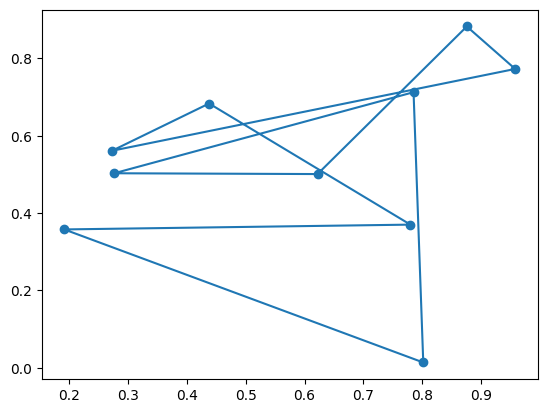

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

In [6]:
# Neighbor operator: swap the positions of two cities in a tour.
# The same operator is used by all local-search algorithms below.
def swap_neighbors(tour):
    """Generate every tour obtained by swapping two different positions."""
    tour = list(tour)
    for i in range(len(tour) - 1):
        for j in range(i + 1, len(tour)):
            neighbor = tour.copy()
            neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
            yield neighbor


def _pack_tsp_result(tour, length, iterations, evaluations, history):
    """Return algorithm results in a common format for comparison."""
    return {
        "tour": list(tour),
        "length": float(length),
        "iterations": int(iterations),
        "evaluations": int(evaluations),
        "history": list(history),
    }


def steepest_hill_climbing(tsp, initial_tour=None, max_iterations=1000):
    """At each step, evaluate every swap-neighbor and take the best improvement."""
    n = len(tsp["pos"])
    current = list(initial_tour) if initial_tour is not None else random_tour(n)
    current_length = float(tour_length(tsp, current))
    history = [current_length]
    iterations = 0
    evaluations = 0

    while iterations < max_iterations:
        best_neighbor = None
        best_length = current_length

        for neighbor in swap_neighbors(current):
            neighbor_length = float(tour_length(tsp, neighbor))
            evaluations += 1
            if neighbor_length < best_length - 1e-12:
                best_neighbor = neighbor
                best_length = neighbor_length

        # No improving neighbor: the current tour is a local optimum for swap.
        if best_neighbor is None:
            break

        current = best_neighbor
        current_length = best_length
        iterations += 1
        history.append(current_length)

    return _pack_tsp_result(current, current_length, iterations, evaluations, history)


# Demonstration on the original 10-city instance in this notebook.
random.seed(1234)
demo_tsp = tsp
demo_initial_tour = random_tour(len(demo_tsp["pos"]))
demo_initial_length = float(tour_length(demo_tsp, demo_initial_tour))
demo_results = {}
steepest_demo = steepest_hill_climbing(demo_tsp, demo_initial_tour)
demo_results["Steepest HC"] = steepest_demo
print(f"Initial tour length: {demo_initial_length:.4f}")
print(f"Steepest Hill Climbing: length={steepest_demo['length']:.4f}, "
      f"accepted moves={steepest_demo['iterations']}, "
      f"neighbor evaluations={steepest_demo['evaluations']}")
print(f"Improvement: {(demo_initial_length - steepest_demo['length']) / demo_initial_length * 100:.2f}%")

Initial tour length: 4.9438
Steepest Hill Climbing: length=2.8811, accepted moves=5, neighbor evaluations=270
Improvement: 41.72%


### Nhận xét – Steepest-ascent Hill Climbing

Tour được biểu diễn bằng một hoán vị các thành phố; hàm mục tiêu `tour_length()` cần được **tối thiểu hóa**. Ở mỗi vòng, thuật toán đánh giá toàn bộ \(n(n-1)/2\) láng giềng swap và chỉ chuyển sang tour ngắn hơn tốt nhất. Nếu không còn láng giềng cải thiện, thuật toán dừng tại cực trị cục bộ; vì vậy không bảo đảm tìm được tour tối ưu toàn cục.

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [7]:
def random_restart_hill_climbing(tsp, restarts=10, max_iterations=1000):
    """Run steepest hill climbing from independent random tours and keep the best."""
    n = len(tsp["pos"])
    n_runs = max(1, int(restarts))
    run_results = []

    for _ in range(n_runs):
        start_tour = random_tour(n)
        run_results.append(steepest_hill_climbing(tsp, start_tour, max_iterations))

    best_result = min(run_results, key=lambda result: result["length"])
    total_iterations = sum(result["iterations"] for result in run_results)
    total_evaluations = sum(result["evaluations"] for result in run_results)
    result = _pack_tsp_result(
        best_result["tour"], best_result["length"],
        total_iterations, total_evaluations, best_result["history"]
    )
    result["runs"] = n_runs
    return result


random.seed(1235)
restart_demo = random_restart_hill_climbing(demo_tsp, restarts=10)
demo_results["Random Restart"] = restart_demo
print(f"Random Restart (10 starts): length={restart_demo['length']:.4f}, "
      f"total accepted moves={restart_demo['iterations']}, "
      f"total neighbor evaluations={restart_demo['evaluations']}")

Random Restart (10 starts): length=2.7636, total accepted moves=51, total neighbor evaluations=2745


### Nhận xét – Random Restarts

Thuật toán chạy Steepest Hill Climbing từ 10 tour khởi tạo ngẫu nhiên rồi giữ tour ngắn nhất. Các lần chạy bắt đầu ở những vị trí khác nhau trong không gian hoán vị nên tăng cơ hội tránh cực trị cục bộ, đổi lại số lần đánh giá và thời gian có thể tăng gần theo số lần khởi động.

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [8]:
def stochastic_hill_climbing(tsp, initial_tour=None, max_iterations=1000):
    """Evaluate all swap-neighbors, then randomly choose one improving neighbor."""
    n = len(tsp["pos"])
    current = list(initial_tour) if initial_tour is not None else random_tour(n)
    current_length = float(tour_length(tsp, current))
    history = [current_length]
    iterations = 0
    evaluations = 0

    while iterations < max_iterations:
        improving_neighbors = []
        for neighbor in swap_neighbors(current):
            neighbor_length = float(tour_length(tsp, neighbor))
            evaluations += 1
            if neighbor_length < current_length - 1e-12:
                improving_neighbors.append((neighbor, neighbor_length))

        if not improving_neighbors:
            break

        current, current_length = random.choice(improving_neighbors)
        current = list(current)
        current_length = float(current_length)
        iterations += 1
        history.append(current_length)

    return _pack_tsp_result(current, current_length, iterations, evaluations, history)


random.seed(1236)
stochastic_demo = stochastic_hill_climbing(demo_tsp, demo_initial_tour)
demo_results["Stochastic HC"] = stochastic_demo
print(f"Stochastic Hill Climbing: length={stochastic_demo['length']:.4f}, "
      f"accepted moves={stochastic_demo['iterations']}, "
      f"neighbor evaluations={stochastic_demo['evaluations']}")

Stochastic Hill Climbing: length=2.8811, accepted moves=13, neighbor evaluations=630


### Nhận xét – Stochastic Hill Climbing

Mỗi bước vẫn duyệt toàn bộ láng giềng swap, nhưng chọn ngẫu nhiên trong các láng giềng có chiều dài nhỏ hơn hiện tại thay vì luôn lấy láng giềng tốt nhất. Cách chọn này tạo các quỹ đạo tìm kiếm đa dạng hơn, nhưng chi phí đánh giá mỗi bước vẫn cao vì phải liệt kê toàn bộ láng giềng.

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [9]:
def first_choice_hill_climbing(
    tsp, initial_tour=None, max_attempts_without_improvement=None, max_iterations=5000
):
    """Try one random swap at a time and accept the first improving neighbor."""
    n = len(tsp["pos"])
    current = list(initial_tour) if initial_tour is not None else random_tour(n)
    current_length = float(tour_length(tsp, current))
    if n < 2:
        return _pack_tsp_result(current, current_length, 0, 0, [current_length])

    if max_attempts_without_improvement is None:
        max_attempts_without_improvement = 100 * n

    history = [current_length]
    iterations = 0
    evaluations = 0
    failed_attempts = 0

    while iterations < max_iterations and failed_attempts < max_attempts_without_improvement:
        i, j = random.sample(range(n), 2)
        neighbor = current.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        neighbor_length = float(tour_length(tsp, neighbor))
        evaluations += 1

        if neighbor_length < current_length - 1e-12:
            current = neighbor
            current_length = neighbor_length
            iterations += 1
            failed_attempts = 0
            history.append(current_length)
        else:
            failed_attempts += 1

    return _pack_tsp_result(current, current_length, iterations, evaluations, history)


random.seed(1237)
first_choice_demo = first_choice_hill_climbing(demo_tsp, demo_initial_tour)
demo_results["First-choice HC"] = first_choice_demo
print(f"First-choice Hill Climbing: length={first_choice_demo['length']:.4f}, "
      f"accepted moves={first_choice_demo['iterations']}, "
      f"neighbor evaluations={first_choice_demo['evaluations']}")
print("Stopping rule: stop after 100 × n consecutive unsuccessful swap attempts, "
      "or after the iteration limit.")

First-choice Hill Climbing: length=2.8811, accepted moves=17, neighbor evaluations=1166
Stopping rule: stop after 100 × n consecutive unsuccessful swap attempts, or after the iteration limit.


### Nhận xét – First-choice Hill Climbing

Thuật toán sinh một phép swap ngẫu nhiên mỗi lần và nhận ngay nếu tour ngắn hơn. Khi có quá \(100n\) lần thử liên tiếp không cải thiện, thuật toán dừng để tránh chạy vô hạn. Mỗi lần thử chỉ đánh giá một láng giềng, nhưng chất lượng phụ thuộc vào các phép swap ngẫu nhiên đã thử và thuật toán có thể dừng trước khi đã kiểm tra hết lân cận.

## Simulated Annealing [2 Points]

In [10]:
def simulated_annealing(
    tsp, initial_tour=None, t0=2.0, alpha=0.995, max_iterations=3000
):
    """Use a geometric cooling schedule and sometimes accept longer tours."""
    n = len(tsp["pos"])
    current = list(initial_tour) if initial_tour is not None else random_tour(n)
    current_length = float(tour_length(tsp, current))
    best_tour = current.copy()
    best_length = current_length
    history = [best_length]
    evaluations = 0
    iterations = 0

    if n < 2:
        return _pack_tsp_result(best_tour, best_length, 0, 0, history)

    for step in range(max_iterations):
        i, j = random.sample(range(n), 2)
        neighbor = current.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        neighbor_length = float(tour_length(tsp, neighbor))
        evaluations += 1

        delta = neighbor_length - current_length
        temperature = max(t0 * (alpha ** step), 1e-12)

        # Minimization: accept an improvement always, otherwise with exp(-delta/T).
        if delta < 0 or random.random() < math.exp(-delta / temperature):
            current = neighbor
            current_length = neighbor_length

        if current_length < best_length - 1e-12:
            best_tour = current.copy()
            best_length = current_length

        iterations += 1
        history.append(best_length)

    return _pack_tsp_result(best_tour, best_length, iterations, evaluations, history)


random.seed(1238)
sa_demo = simulated_annealing(demo_tsp, demo_initial_tour, t0=2.0, alpha=0.995, max_iterations=3000)
demo_results["Simulated Annealing"] = sa_demo
print(f"Simulated Annealing (T0=2.0, alpha=0.995, 3000 steps): "
      f"best length={sa_demo['length']:.4f}, "
      f"best-so-far history points={len(sa_demo['history'])}, "
      f"neighbor evaluations={sa_demo['evaluations']}")

Simulated Annealing (T0=2.0, alpha=0.995, 3000 steps): best length=2.7636, best-so-far history points=3001, neighbor evaluations=3000


### Nhận xét – Simulated Annealing

Với \(\Delta = f(	ext{tour mới}) - f(	ext{tour hiện tại})\), bước tốt hơn luôn được chấp nhận; bước xấu hơn được chấp nhận với xác suất \(e^{-\Delta/T}\). Lịch nhiệt mũ \(T_t=T_0lpha^t\) dùng \(T_0=2.0\), \(lpha=0.995\) và ngân sách 3.000 bước. Nhiệt độ cao giúp khám phá, còn khi nhiệt độ giảm thuật toán ít nhận bước xấu hơn. Đây là cơ chế giảm nguy cơ mắc kẹt sớm, không phải bảo đảm tối ưu toàn cục.

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [11]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.1392364501953125 milliseconds


Summary over 5 repetitions per city count (shorter tour is better):


,Cities,Algorithm,Best,Mean,Mean_iterations,Mean_evaluations,Mean_time_ms
0,10,Steepest HC,2.16,2.96,5.8,306.0,1.09
1,10,Random Restart,2.16,2.88,50.2,2709.0,5.52
2,10,Stochastic HC,2.19,3.00,12.2,594.0,1.22
3,10,First-choice HC,2.19,2.97,9.2,1162.8,4.70
4,10,Simulated Annealing,2.16,2.88,3000.0,3000.0,11.50
5,15,Steepest HC,2.98,3.87,9.6,1113.0,2.66
6,15,Random Restart,2.98,3.35,90.4,10542.0,26.31
7,15,Stochastic HC,2.99,3.87,21.0,2310.0,6.24
8,15,First-choice HC,2.99,3.75,21.0,1903.8,7.85
9,15,Simulated Annealing,3.43,3.73,3000.0,3000.0,13.49


Demo initial length: 4.9438
Best demonstration algorithm: Random Restart; length=2.7636; improvement=44.10%


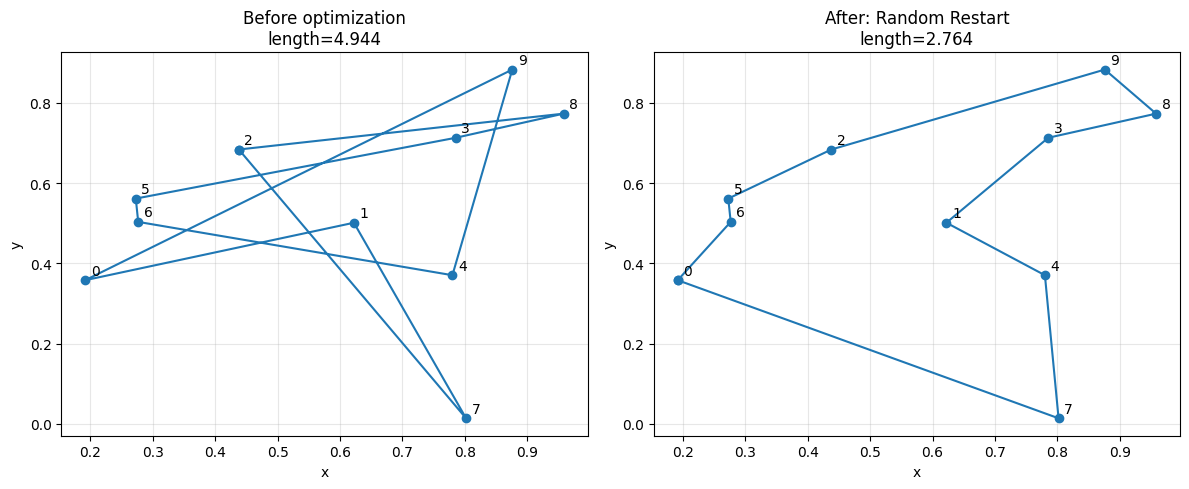

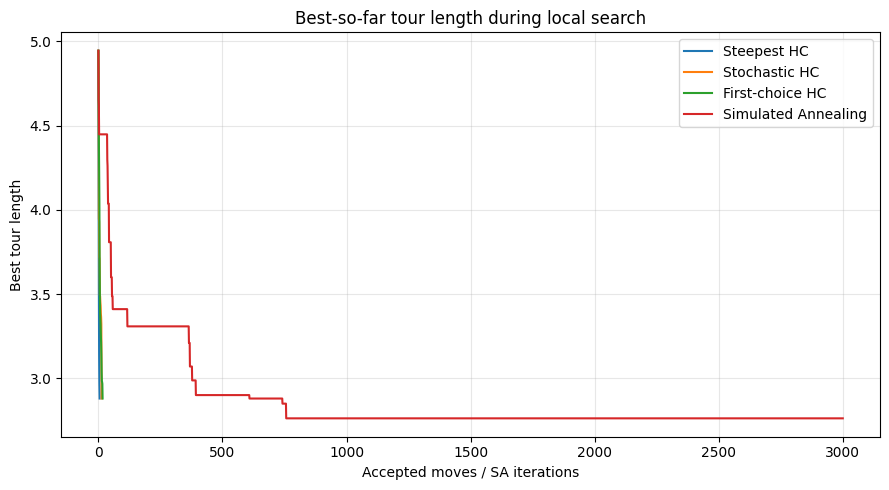

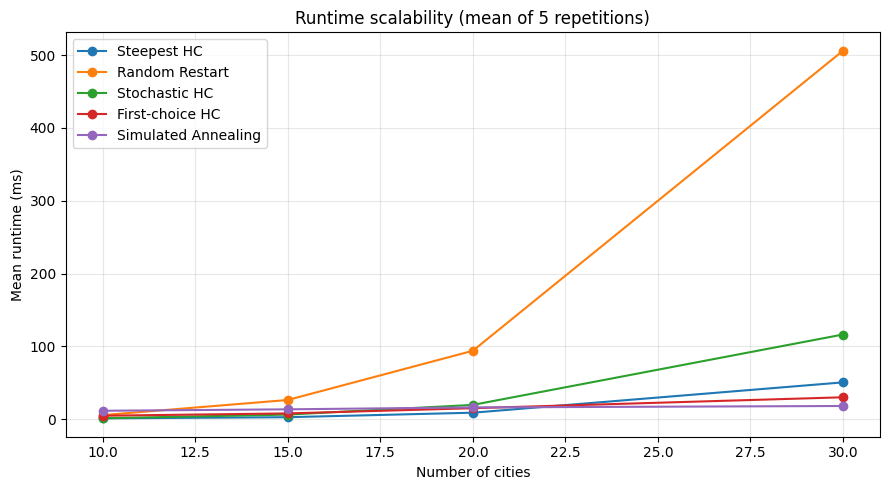

Interpretation: compare both tour length and runtime. Steepest/Stochastic inspect all C(n, 2) swap-neighbors per accepted step; First-choice tests one random swap at a time; Random Restart spends extra time on multiple starting tours; Simulated Annealing uses a fixed 3000-step budget and can accept worse moves early in cooling.


In [12]:
# Repeat each configuration 5 times on randomly generated Euclidean TSP instances.
# All local-search algorithms use the same swap-neighbor operator.
import time
from IPython.display import display

city_counts = [10, 15, 20, 30]
repeats = 5
raw_records = []
algorithm_names = [
    "Steepest HC", "Random Restart", "Stochastic HC",
    "First-choice HC", "Simulated Annealing"
]

for n_cities in city_counts:
    for repeat_id in range(repeats):
        # Reproducible problem instance and common initial tour for this repeat.
        np.random.seed(10000 + n_cities * 100 + repeat_id)
        tsp_case = random_tsp(n_cities)
        random.seed(20000 + n_cities * 100 + repeat_id)
        common_start = random_tour(n_cities)

        for alg_id, algorithm_name in enumerate(algorithm_names):
            random.seed(30000 + n_cities * 100 + repeat_id * 10 + alg_id)
            start_time = time.perf_counter()

            if algorithm_name == "Steepest HC":
                result = steepest_hill_climbing(tsp_case, common_start)
            elif algorithm_name == "Random Restart":
                result = random_restart_hill_climbing(tsp_case, restarts=10)
            elif algorithm_name == "Stochastic HC":
                result = stochastic_hill_climbing(tsp_case, common_start)
            elif algorithm_name == "First-choice HC":
                result = first_choice_hill_climbing(
                    tsp_case, common_start,
                    max_attempts_without_improvement=100 * n_cities,
                    max_iterations=5000
                )
            else:
                result = simulated_annealing(
                    tsp_case, common_start, t0=2.0, alpha=0.995, max_iterations=3000
                )

            elapsed_ms = (time.perf_counter() - start_time) * 1000
            raw_records.append({
                "Cities": n_cities,
                "Repeat": repeat_id + 1,
                "Algorithm": algorithm_name,
                "Best tour length": result["length"],
                "Iterations": result["iterations"],
                "Evaluations": result["evaluations"],
                "Time (ms)": elapsed_ms,
            })

results_df = pd.DataFrame(raw_records)
summary = (
    results_df.groupby(["Cities", "Algorithm"], sort=False)
    .agg(
        Best=("Best tour length", "min"),
        Mean=("Best tour length", "mean"),
        Mean_iterations=("Iterations", "mean"),
        Mean_evaluations=("Evaluations", "mean"),
        Mean_time_ms=("Time (ms)", "mean"),
    )
    .reset_index()
)
summary["Best"] = summary["Best"].round(4)
summary["Mean"] = summary["Mean"].round(4)
summary["Mean_iterations"] = summary["Mean_iterations"].round(1)
summary["Mean_evaluations"] = summary["Mean_evaluations"].round(1)
summary["Mean_time_ms"] = summary["Mean_time_ms"].round(3)

print(f"Summary over {repeats} repetitions per city count (shorter tour is better):")
display(summary)

# Plot 1: compare a random initial tour with the best demonstration result.
best_demo_name, best_demo_result = min(demo_results.items(), key=lambda item: item[1]["length"])
print(f"Demo initial length: {demo_initial_length:.4f}")
print(f"Best demonstration algorithm: {best_demo_name}; length={best_demo_result['length']:.4f}; "
      f"improvement={(demo_initial_length - best_demo_result['length']) / demo_initial_length * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, route, title in [
    (axes[0], demo_initial_tour, f"Before optimization\nlength={demo_initial_length:.3f}"),
    (axes[1], best_demo_result["tour"], f"After: {best_demo_name}\nlength={best_demo_result['length']:.3f}"),
]:
    pos = demo_tsp["pos"]
    route_closed = list(route) + [route[0]]
    route_pos = pos.iloc[route_closed]
    ax.plot(route_pos["x"], route_pos["y"], marker="o")
    for city_id, row in pos.iterrows():
        ax.annotate(str(city_id), (row["x"], row["y"]), xytext=(4, 4), textcoords="offset points")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: best-so-far objective during the demonstration runs.
fig, ax = plt.subplots(figsize=(9, 5))
for name in ["Steepest HC", "Stochastic HC", "First-choice HC", "Simulated Annealing"]:
    history = demo_results[name]["history"]
    ax.plot(range(len(history)), history, label=name)
ax.set_title("Best-so-far tour length during local search")
ax.set_xlabel("Accepted moves / SA iterations")
ax.set_ylabel("Best tour length")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 3: mean runtime versus number of cities.
fig, ax = plt.subplots(figsize=(9, 5))
for name in algorithm_names:
    subset = summary[summary["Algorithm"] == name].sort_values("Cities")
    ax.plot(subset["Cities"], subset["Mean_time_ms"], marker="o", label=name)
ax.set_title("Runtime scalability (mean of 5 repetitions)")
ax.set_xlabel("Number of cities")
ax.set_ylabel("Mean runtime (ms)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Interpretation: compare both tour length and runtime. Steepest/Stochastic inspect all "
      "C(n, 2) swap-neighbors per accepted step; First-choice tests one random swap at a time; "
      "Random Restart spends extra time on multiple starting tours; Simulated Annealing uses "
      "a fixed 3000-step budget and can accept worse moves early in cooling.")

### Nhận xét kết quả so sánh

Bảng và biểu đồ ở ô trên được tạo từ 5 lần chạy cho mỗi kích thước \(n\in\{10,15,20,30\}\). `Best` là chiều dài tốt nhất trong 5 lần; `Mean` là trung bình chiều dài tour tốt nhất của từng lần; thời gian được tính bằng mili giây. Hãy đọc đồng thời chất lượng tour, số lần đánh giá và thời gian: Steepest/Stochastic duyệt toàn bộ lân cận, Random Restart thực hiện nhiều lần chạy, First-choice thử từng láng giềng và SA dùng ngân sách số bước cố định. Kết quả có thể biến đổi theo dữ liệu, seed và cấu hình chạy; các số trong bảng là kết quả thực thi của chính notebook.

## Bonus: Genetic Algorithm [+1 Point]

In [13]:
# Bonus: Genetic Algorithm using order crossover and swap mutation.
def order_crossover(parent1, parent2):
    """Order crossover (OX) keeps a segment from parent1 and fills from parent2."""
    n = len(parent1)
    if n < 2:
        return list(parent1)

    left, right = sorted(random.sample(range(n), 2))
    child = [None] * n
    child[left:right + 1] = parent1[left:right + 1]

    parent2_order = list(parent2[right + 1:]) + list(parent2[:right + 1])
    missing = [city for city in parent2_order if city not in child]
    fill_positions = list(range(right + 1, n)) + list(range(0, left))
    for position, city in zip(fill_positions, missing):
        child[position] = city

    return child


def swap_mutation(tour, mutation_rate=0.2):
    """Mutate a tour by swapping two positions with the given probability."""
    mutated = list(tour)
    if len(mutated) >= 2 and random.random() < mutation_rate:
        i, j = random.sample(range(len(mutated)), 2)
        mutated[i], mutated[j] = mutated[j], mutated[i]
    return mutated


def genetic_algorithm(
    tsp, population_size=50, generations=150, mutation_rate=0.2,
    elite_size=2, tournament_size=3
):
    """Return the best tour found by a permutation-based genetic algorithm."""
    n = len(tsp["pos"])
    population_size = max(4, int(population_size))
    population = [random_tour(n) for _ in range(population_size)]
    evaluations = len(population)
    scores = [float(tour_length(tsp, tour)) for tour in population]
    best_index = int(np.argmin(scores))
    best_tour = population[best_index].copy()
    best_length = scores[best_index]
    history = [best_length]

    def tournament_select(pop, values):
        k = min(tournament_size, len(pop))
        choices = random.sample(range(len(pop)), k)
        winner = min(choices, key=lambda idx: values[idx])
        return pop[winner]

    for _ in range(generations):
        ranked = sorted(zip(population, scores), key=lambda pair: pair[1])
        next_population = [tour.copy() for tour, _ in ranked[:max(1, elite_size)]]

        while len(next_population) < population_size:
            parent1 = tournament_select(population, scores)
            parent2 = tournament_select(population, scores)
            child = order_crossover(parent1, parent2)
            child = swap_mutation(child, mutation_rate)
            next_population.append(child)

        population = next_population
        scores = [float(tour_length(tsp, tour)) for tour in population]
        evaluations += len(population)
        generation_best_index = int(np.argmin(scores))
        if scores[generation_best_index] < best_length - 1e-12:
            best_tour = population[generation_best_index].copy()
            best_length = scores[generation_best_index]
        history.append(best_length)

    return _pack_tsp_result(best_tour, best_length, generations, evaluations, history)


random.seed(1239)
ga_demo = genetic_algorithm(demo_tsp, population_size=50, generations=150, mutation_rate=0.2)
print(f"Genetic Algorithm (bonus): best length={ga_demo['length']:.4f}, "
      f"generations={ga_demo['iterations']}, "
      f"fitness evaluations={ga_demo['evaluations']}")
print("This bonus result is not included in the main performance table, so the five required "
      "local-search algorithms are compared separately.")

Genetic Algorithm (bonus): best length=2.7636, generations=150, fitness evaluations=7550
This bonus result is not included in the main performance table, so the five required local-search algorithms are compared separately.


### Bonus – Genetic Algorithm

Thuật toán di truyền biểu diễn mỗi cá thể bằng một hoán vị hợp lệ, dùng **order crossover (OX)** để kết hợp hai tour và **swap mutation** để duy trì đa dạng. Mỗi thế hệ giữ lại cá thể tốt nhất (elitism), chọn bố mẹ bằng tournament selection và đánh giá quần thể mới. Đây là phần mở rộng bonus; nó không được gộp vào bảng so sánh chính nhằm giữ bảng tập trung vào năm thuật toán tìm kiếm cục bộ được yêu cầu.

### Câu hỏi thảo luận 10 – Swap và 2-opt trong TSP

Toán tử swap đổi vị trí của hai thành phố; mỗi tour có \(n(n-1)/2=O(n^2)\) láng giềng swap. Toán tử 2-opt chọn hai cạnh để cắt rồi đảo đoạn tour ở giữa, nên thay đổi cấu trúc tour nhiều hơn và thường loại bỏ được các cạnh giao nhau, từ đó có thể tìm tour ngắn hơn hoặc thoát một cực trị cục bộ mà swap không thoát được. Số láng giềng 2-opt cũng là \(O(n^2)\). Nếu tính lại toàn bộ độ dài tour, mỗi lần đánh giá tốn \(O(n)\); với cập nhật chênh lệch cạnh phù hợp, có thể đánh giá một nước 2-opt trong \(O(1)\) cho TSP đối xứng. Trong thực nghiệm so sánh chính ở notebook này, tất cả thuật toán dùng swap để bảo đảm so sánh cùng một toán tử lân cận.